# Elastic scheduling with integer periods: Slack Reclamation vs Buttazzo vs Sudvarg-style vs conventional

This one notebook does everything:

1. defines the four methods (conventional, Buttazzo, Sudvarg-style, **ours: Slack Reclamation**),
2. loads the datasets (GAP, Hartstone, a 22-task composite, and the TrustMotion benchmark),
3. computes the elastic parameters from each task's C and T,
4. runs every method on every task set,
5. checks the results, builds the comparison tables and charts,
6. exports `comparative_study.xlsx` and a CSV with every run.

**Run order:** just run all cells top to bottom (Kernel > Restart & Run All). The full run takes a few minutes.

**Idea of the new scheduler.** Elastic compression produces real-valued periods (e.g. 30.36 ms) but real systems need integer periods. Rounding every period *up* is safe but wastes some of the utilization budget. Our scheduler (1) compresses, (2) rounds up, then (3) *spends the leftover budget* by moving tasks to the next smaller integer period, always choosing the move with the best cost reduction per unit of utilization added.

## 1. Settings

In [1]:
import os, sys, time, heapq, subprocess, glob, json, shutil, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- settings you may change ------------------------------------------------
TASKS_CSV  = "trustmotion_tasks.csv"   # task table (bucket, instance, core_set, C_ms, T_ms, ...).
                                       # If this file is missing it is built automatically from the GitHub repo.
REPO_URL   = "https://github.com/dtu-ese/automotive-cause-effect-chain-benchmark.git"
BUCKETS    = None                      # None = all five buckets; or e.g. ["100pct"] for a quick run
RULES      = ("R1", "R2", "R3")        # elastic coefficient rules (see section 2)
FRACTIONS  = (0.9, 0.8, 0.7, 0.6)      # overload targets: U_d = fraction x original utilization U0
OUT_DIR    = "results"
os.makedirs(OUT_DIR, exist_ok=True)
EPS = 1e-9
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

## 2. Elastic parameters (computed only from C and T)

For every task, with `U = C / T`:

| Parameter | Formula | Meaning |
|---|---|---|
| Tmin | `T` | nominal period is the fastest rate |
| Tmax | `T * (2 - U)` | light tasks can stretch almost 2x, heavy tasks less |
| E (rule R1) | `C / T` | heavy tasks give up the most utilization |
| E (rule R2) | `T / C` | tasks with the most headroom are the most elastic |
| E (rule R3) | `T` | long-period tasks are the most elastic |
| Target U_d | `fraction * U0` | `U0` = sum of `C/T` |

These rules are our own modelling assumptions: no real task set records elastic parameters.

**Compression problem.** minimise `sum (U0_i - U_i)^2 / E_i` subject to `sum U_i <= U_d` and `Umin_i <= U_i <= U0_i`. The solution is `U_i = max(Umin_i, U0_i - lam * E_i)` for one number `lam`.

In [2]:
def elastic_params(C, T, rule):
    """Elastic parameters from C and T only."""
    U0 = C / T
    Tmin = T.copy()
    Tmax = T * (2.0 - U0)
    Umin = C / Tmax
    E = {"R1": C / T, "R2": T / C, "R3": T.copy()}[rule]
    return U0, Tmin, Tmax, Umin, E

def elastic_cost(U0, U, E):
    return float(np.sum((U0 - U) ** 2 / E))

## 3. The methods

* **Buttazzo** : iterative compression. Tasks that would go beyond their limit are fixed at the limit and the rest is recomputed until nothing violates.
* **Sudvarg-style** : sort tasks by the `lam` at which they hit their limit and find the breakpoint in one pass, O(n log n). *This is my implementation of the sorted-threshold idea, not their published pseudocode; check it against the paper.* It gives the same result as Buttazzo (verified below), they differ only in runtime.
* **Naive rounding** : every period rounded **up** to a whole millisecond (keeps total utilization <= U_d).
* **Ours, Slack Reclamation** : after rounding, the unused utilization (slack) is spent by moving tasks to the next smaller integer period (never below Tmin). The move taken each time is the one with the largest cost reduction per unit of utilization added: the discrete form of the optimality condition that `(U0_i - U_i)/E_i` is equal for all tasks. A heap makes it O(n log n + k log n) for k moves.
* **Conventional** : no elasticity; drops the most elastic tasks until the set fits.

In [3]:
def compress_buttazzo(U0, Umin, E, Ud):
    """Original iterative elastic compression (Buttazzo et al.)."""
    n = len(U0)
    fixed = np.zeros(n, dtype=bool)
    while True:
        free = ~fixed
        lam = (U0[free].sum() - Ud + Umin[fixed].sum()) / E[free].sum()
        Unew = U0 - lam * E
        viol = free & (Unew < Umin - 1e-15)
        if not viol.any():
            return np.where(fixed, Umin, Unew)
        fixed |= viol
        if fixed.all():
            return Umin.copy()

def compress_sorted(U0, Umin, E, Ud):
    """Sorted-threshold compression, O(n log n)."""
    r = (U0 - Umin) / E                         # lam at which task i reaches its limit
    order = np.argsort(r, kind="stable")
    rs, U0s, Umins, Es = r[order], U0[order], Umin[order], E[order]
    cum_min = np.concatenate(([0.0], np.cumsum(Umins)))
    suf_U0  = np.concatenate((np.cumsum(U0s[::-1])[::-1], [0.0]))
    suf_E   = np.concatenate((np.cumsum(Es[::-1])[::-1], [0.0]))
    n = len(U0)
    S = cum_min[:n] + suf_U0[:n] - rs * suf_E[:n]   # total utilization at lam = r_(k)
    ok = S <= Ud
    if not ok.any():
        return Umin.copy()
    k = int(np.argmax(ok))
    lam = (cum_min[k] + suf_U0[k] - Ud) / suf_E[k]
    Us = np.where(np.arange(n) < k, Umins, U0s - lam * Es)
    U = np.empty(n); U[order] = Us
    return U

def round_up(C, U):
    """Naive integer rounding: every period rounded UP."""
    return np.ceil(C / U - EPS)

def reclaim(C, P, U0, E, Gmin, Ud):
    """OUR SCHEDULER (slack reclamation). Returns (new integer periods, number of moves)."""
    P = P.copy()
    slack = Ud - float(np.sum(C / P))
    heap = []

    def candidate(i):
        p = P[i] - 1.0                      # next smaller integer period
        if p < Gmin[i]:
            return None                     # would go below Tmin
        u_now, u_new = C[i] / P[i], C[i] / p
        du = u_new - u_now                  # extra utilization needed
        gain = ((U0[i] - u_now) ** 2 - (U0[i] - u_new) ** 2) / E[i]   # cost reduction
        return gain / du, du

    for i in range(len(P)):
        c = candidate(i)
        if c:
            heapq.heappush(heap, (-c[0], i))
    moves = 0
    while heap and slack > 0:
        _, i = heapq.heappop(heap)
        c = candidate(i)
        if c is None:
            continue
        if c[1] <= slack:
            P[i] -= 1.0; slack -= c[1]; moves += 1
            c2 = candidate(i)
            if c2:
                heapq.heappush(heap, (-c2[0], i))
        # else: this move can never fit later (slack only shrinks): discard it
    return P, moves

def conventional(U0, E, Ud):
    """No elasticity: drop the most elastic (least critical) tasks until the set fits."""
    order = np.argsort(-E, kind="stable")
    kept = np.ones(len(U0), dtype=bool)
    total = U0.sum()
    for i in order:
        if total <= Ud + 1e-12:
            break
        kept[i] = False; total -= U0[i]
    return kept, float(total)

### Reference solutions (to judge how close we get)

* **Integer lower bound**: the same problem with utilizations allowed to be continuous inside the integer-grid range. No integer solution can be better, so `cost / bound >= 1` and `1.0` means best possible. It includes the unavoidable cost of rounding nominal periods like 2.5 ms up to the grid.
* **Exact DP reference** (small sets only): multiple-choice knapsack over utilization quantised to 1e-5 (conservative), giving a near-optimal integer-period cost.

In [4]:
def grid_lower_bound(C, U0, E, Gmin, Gmax, Ud):
    lo, hi = C / Gmax, C / Gmin
    if hi.sum() <= Ud:
        U = hi
    else:
        a, b = 0.0, 1.0
        while np.clip(U0 - b * E, lo, hi).sum() > Ud:
            b *= 2.0
            if b > 1e12: break
        for _ in range(80):
            m = 0.5 * (a + b)
            if np.clip(U0 - m * E, lo, hi).sum() > Ud: a = m
            else: b = m
        U = np.clip(U0 - b * E, lo, hi)
    return float(np.sum((U0 - U) ** 2 / E))

def dp_reference(C, T, rule, Ud, delta=1e-5):
    U0, Tmin, Tmax, Umin, E = elastic_params(C, T, rule)
    Gmin = np.ceil(Tmin - EPS).astype(int); Gmax = np.ceil(Tmax - EPS).astype(int)
    B = int(np.floor(Ud / delta))
    dp = np.zeros(B + 1)
    for i in range(len(C)):
        P = np.arange(Gmin[i], Gmax[i] + 1)
        U = C[i] / P
        w = np.ceil(U / delta - 1e-9).astype(int)
        c = (U0[i] - U) ** 2 / E[i]
        best = {}
        for wi, ci in zip(w, c):
            if wi not in best or ci < best[wi]:
                best[wi] = ci
        new = np.full(B + 1, np.inf)
        for wi, ci in best.items():
            if wi > B: continue
            np.minimum(new[wi:], dp[: B + 1 - wi] + ci, out=new[wi:])
        dp = new
    return float(dp[B])

### Run all methods on one task set

In [5]:
def run_set(C, T, rule, frac=None, Ud=None):
    """Run all methods on one task set. Returns a dict of results, or None if the target is not reachable."""
    from time import perf_counter_ns as now
    U0, Tmin, Tmax, Umin, E = elastic_params(C, T, rule)
    Ut0 = float(U0.sum())
    if Ud is None:
        Ud = frac * Ut0
    if Ud < float(Umin.sum()) - 1e-12 or Ud >= Ut0:
        return None
    Gmin, Gmax = np.ceil(Tmin - EPS), np.ceil(Tmax - EPS)
    out = {"n": len(C), "U0": Ut0, "Ud": Ud}

    t0 = now(); Ub = compress_buttazzo(U0, Umin, E, Ud); t1 = now()
    Us = compress_sorted(U0, Umin, E, Ud); t2 = now()
    out["t_buttazzo_us"] = (t1 - t0) / 1e3
    out["t_sorted_us"] = (t2 - t1) / 1e3
    out["compress_diff"] = float(np.max(np.abs(Ub - Us)))
    ideal = elastic_cost(U0, Us, E)
    lb = grid_lower_bound(C, U0, E, Gmin, Gmax, Ud)
    out["ideal_cost"], out["grid_bound_cost"] = ideal, lb

    kept, uk = conventional(U0, E, Ud)
    out["conv_dropped"] = int((~kept).sum())
    out["conv_unused"] = Ud - uk

    for name, U in (("buttazzo", Ub), ("sudvarg", Us)):
        Uf = C / round_up(C, U)
        cst = elastic_cost(U0, Uf, E)
        out[f"{name}_unused"] = Ud - float(Uf.sum())
        out[f"{name}_cost_ratio"] = cst / ideal
        out[f"{name}_gap"] = cst / lb

    t3 = now()
    P2, moves = reclaim(C, round_up(C, Us), U0, E, Gmin, Ud)
    t4 = now()
    Uf2 = C / P2
    cst2 = elastic_cost(U0, Uf2, E)
    out["ours_unused"] = Ud - float(Uf2.sum())
    out["ours_cost_ratio"] = cst2 / ideal
    out["ours_gap"] = cst2 / lb
    out["ours_moves"] = moves
    out["t_ours_extra_us"] = (t4 - t3) / 1e3
    out["feasible_ok"] = bool(Uf2.sum() <= Ud + 1e-9)
    return out

## 4. Datasets

* **GAP**, 17 tasks: Generic Avionics Platform, Locke, Vogel and Mesler, RTSS 1991, as tabulated in Bhat and Rajkumar, arXiv:2302.03724 (Table I). Verify against the original before citing numbers.
* **Hartstone**, 5 tasks: Weiderman and Kamenoff, Real-Time Systems 4, 1992, as tabulated in Table VIII of the same paper.
* **Composite-22**: GAP + Hartstone together (U0 above 1, a legitimate overloaded start for elastic scheduling). Not a real single system: label it a composite.
* **TrustMotion**: benchmark by Craciunas, Becker and Pop (Zenodo, doi:10.5281/zenodo.20637979, MIT license). The instances are *generated from real automotive statistics* (the files call themselves synthetic). Each core of each instance is treated as one uniprocessor task set; deadlines are ignored (elastic model assumes deadline = period).

Times are in milliseconds.

In [6]:
gap  = [(5,25),(2,25),(1,40),(5,50),(3,50),(8,59),(2,80),(9,80),(5,100),(3,200),(1,200),(1,200),(3,200),(1,200),(3,200),(1,1000),(1,1000)]
hart = [(5,333.33),(2,200),(1,142.86),(5,58.82),(3,32.26)]
def arr(l): return np.array([a for a, b in l], float), np.array([b for a, b in l], float)
small = {"GAP": (arr(gap), [("frac", f) for f in FRACTIONS]),
         "Hartstone": (arr(hart), [("frac", f) for f in FRACTIONS]),
         "Composite-22": (arr(gap + hart), [("abs", u) for u in (1.0, 0.9, 0.8, 0.7)])}
for k, ((C, T), _) in small.items():
    print(f"{k:13s} tasks={len(C):2d}  U0={np.sum(C/T):.4f}")

GAP           tasks=17  U0=0.8501
Hartstone     tasks= 5  U0=0.2100
Composite-22  tasks=22  U0=1.0601


In [7]:
def build_tasks_csv_from_repo(path):
    """Download the TrustMotion benchmark from GitHub and write the task table (needs internet + git)."""
    tmp = tempfile.mkdtemp()
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, tmp + "/repo"], check=True)
    root = tmp + "/repo/data/TrustMotion"
    rows = []
    for b in sorted(os.listdir(root)):
        for fn in sorted(glob.glob(f"{root}/{b}/*.json")):
            inst = os.path.basename(fn)[:-5]
            d = json.load(open(fn))
            assert d["metadata"]["time_unit"] == "us"
            for t in d["tasks"]:
                p = t["placement"]
                C, T = t["wcet"] / 1000, t["period"] / 1000
                rows.append((b, inst, p["cpu_id"], p["core_id"], f"{b}/{inst}/cpu{p['cpu_id']}-core{p['core_id']}", t["name"], round(C, 3), round(T, 3), C / T))
    pd.DataFrame(rows, columns=["bucket","instance","cpu_id","core_id","core_set","task","C_ms","T_ms","U"]).to_csv(path, index=False)
    shutil.rmtree(tmp, ignore_errors=True)

if not os.path.exists(TASKS_CSV):
    print("task table not found, building it from the GitHub repo ...")
    build_tasks_csv_from_repo(TASKS_CSV)

tm = pd.read_csv(TASKS_CSV, usecols=["bucket", "instance", "core_set", "C_ms", "T_ms"])
if BUCKETS:
    tm = tm[tm.bucket.isin(BUCKETS)]
tm_sets = [(cs, g.bucket.iloc[0], g.C_ms.to_numpy(float), g.T_ms.to_numpy(float)) for cs, g in tm.groupby("core_set", sort=False)]
sizes = [len(s[2]) for s in tm_sets]
print(f"TrustMotion: {len(tm):,} tasks in {len(tm_sets):,} core task sets; tasks per set: min {min(sizes)}, median {int(np.median(sizes))}, max {max(sizes)}")

TrustMotion: 150,000 tasks in 13,500 core task sets; tasks per set: min 2, median 11, max 27


## 5. Worked example: GAP, rule R1, target 0.7 x U0
Per-task periods under each method, so you can see what the new scheduler changes.

In [8]:
C, T = arr(gap)
rule, frac = "R1", 0.7
U0, Tmin, Tmax, Umin, E = elastic_params(C, T, rule)
Ud = frac * U0.sum()
Us = compress_sorted(U0, Umin, E, Ud)
Pn = round_up(C, Us)
Po, moves = reclaim(C, Pn, U0, E, np.ceil(Tmin - EPS), Ud)
ex = pd.DataFrame({"C": C, "T nominal": T, "Tmax": Tmax.round(1), "E": E.round(4),
                   "compressed (real)": (C / Us).round(2), "naive rounding": Pn, "ours": Po})
display(ex)
print(f"target U_d = {Ud:.5f}")
print(f"naive rounding : total U = {np.sum(C/Pn):.5f}   unused = {Ud-np.sum(C/Pn):.5f}")
print(f"ours           : total U = {np.sum(C/Po):.5f}   unused = {Ud-np.sum(C/Po):.5f}   ({moves} moves)")

,C,T nominal,Tmax,E,compressed (real),naive rounding,ours
0,5.0,25.0,45.0,0.2000,35.71,36.0,36.0
1,2.0,25.0,48.0,0.0800,35.71,36.0,36.0
2,1.0,40.0,79.0,0.0250,57.14,58.0,57.0
3,5.0,50.0,95.0,0.1000,71.43,72.0,71.0
4,3.0,50.0,97.0,0.0600,71.43,72.0,71.0
5,8.0,59.0,110.0,0.1356,84.29,85.0,84.0
6,2.0,80.0,158.0,0.0250,114.29,115.0,114.0
7,9.0,80.0,151.0,0.1125,114.29,115.0,114.0
8,5.0,100.0,195.0,0.0500,142.86,143.0,143.0
9,3.0,200.0,397.0,0.0150,285.71,286.0,283.0


target U_d = 0.59507
naive rounding : total U = 0.59089   unused = 0.00418
ours           : total U = 0.59506   unused = 0.00000   (51 moves)


## 6. Run everything on the TrustMotion task sets

In [9]:
rows = []
t_start = time.time()
for i, (cs, b, C, T) in enumerate(tm_sets):
    for rule in RULES:
        for f in FRACTIONS:
            r = run_set(C, T, rule, frac=f)
            if r is None:
                continue
            r.update(core_set=cs, bucket=b, rule=rule, frac=f)
            rows.append(r)
    if (i + 1) % 3000 == 0:
        print(f"  {i+1:,} / {len(tm_sets):,} task sets done  ({time.time()-t_start:.0f} s)")
res = pd.DataFrame(rows)
print(f"{len(res):,} runs in {time.time()-t_start:.0f} s")

  3,000 / 13,500 task sets done  (23 s)
  6,000 / 13,500 task sets done  (46 s)
  9,000 / 13,500 task sets done  (68 s)
  12,000 / 13,500 task sets done  (91 s)
150,333 runs in 103 s


### Checks
These must all pass before the numbers can be trusted.

In [10]:
same = res.compress_diff.max()
checks = {
    "Buttazzo and Sudvarg-style compression identical (max difference)": f"{same:.1e}",
    "every result keeps total utilization <= target": bool(res.feasible_ok.all()),
    "ours never worse than naive rounding": bool((res.ours_gap <= res.sudvarg_gap + 1e-12).all()),
    "ours strictly better than naive rounding (% of runs)": f"{100*(res.ours_gap < res.sudvarg_gap - 1e-12).mean():.2f}",
}
for k, v in checks.items():
    print(f"{k:70s} {v}")
assert same < 1e-9 and res.feasible_ok.all() and (res.ours_gap <= res.sudvarg_gap + 1e-12).all()

Buttazzo and Sudvarg-style compression identical (max difference)      2.2e-16
every result keeps total utilization <= target                         True
ours never worse than naive rounding                                   True
ours strictly better than naive rounding (% of runs)                   99.92


## 7. Results: TrustMotion

In [11]:
res["unused_pct_naive"] = 100 * res.sudvarg_unused / res.Ud
res["unused_pct_ours"]  = 100 * res.ours_unused / res.Ud
res["unused_pct_conv"]  = 100 * res.conv_unused / res.Ud
res["cost_red"]   = 100 * (1 - res.ours_gap / res.sudvarg_gap)
res["better"]     = 100 * (res.ours_gap < res.sudvarg_gap - 1e-12)
res["dropped_pct"] = 100 * res.conv_dropped / res.n

summary = (res.groupby(["rule", "frac"])
    .agg(runs=("n", "size"), conv_unused=("unused_pct_conv", "mean"), naive_unused=("unused_pct_naive", "mean"),
         ours_unused=("unused_pct_ours", "mean"), naive_gap=("sudvarg_gap", "mean"), ours_gap=("ours_gap", "mean"),
         cost_reduction=("cost_red", "mean"), ours_better=("better", "mean"),
         conv_dropped=("dropped_pct", "mean"), moves=("ours_moves", "mean")).reset_index())
summary.columns = ["Rule", "Target (x U0)", "Runs", "Unused % Conventional", "Unused % naive rounding (Buttazzo = Sudvarg)",
                   "Unused % Ours", "Cost/bound naive", "Cost/bound Ours", "Avg cost reduction %", "Ours better %",
                   "Conventional tasks dropped %", "Ours avg moves"]
display(summary.round(3))

overall = res[["unused_pct_naive", "unused_pct_ours", "sudvarg_gap", "ours_gap", "cost_red", "better", "dropped_pct"]].mean()
print("\nOVERALL (all runs):")
print(f"  unused utilization, % of target : naive {overall.unused_pct_naive:.3f}   ours {overall.unused_pct_ours:.3f}")
print(f"  cost / integer bound (1.0=best) : naive {overall.sudvarg_gap:.3f}   ours {overall.ours_gap:.3f}")
print(f"  average cost reduction          : {overall.cost_red:.2f} %      ours strictly better in {overall.better:.2f} % of runs")
print(f"  conventional drops on average   : {overall.dropped_pct:.1f} % of tasks")
print(f"  ours worst cost/bound = {res.ours_gap.max():.2f},  95th percentile = {res.ours_gap.quantile(.95):.2f}")

,Rule,Target (x U0),Runs,Unused % Conventional,Unused % naive rounding (Buttazzo = Sudvarg),Unused % Ours,Cost/bound naive,Cost/bound Ours,Avg cost reduction %,Ours better %,Conventional tasks dropped %,Ours avg moves
0,R1,0.6,9858,21.478,2.079,0.012,1.065,1.002,5.810,100.000,16.809,13.798
1,R1,0.7,13253,21.638,3.135,0.018,1.160,1.005,13.029,99.985,10.778,14.726
2,R1,0.8,13500,30.588,2.529,0.026,1.233,1.022,16.069,99.267,10.294,10.195
3,R1,0.9,13500,37.379,4.074,0.046,1.929,1.100,41.389,100.000,9.921,12.811
4,R2,0.6,9858,17.217,2.087,0.008,1.165,1.068,7.888,100.000,82.950,8.302
5,R2,0.7,13253,16.983,2.196,0.009,1.253,1.094,11.579,99.992,78.482,10.570
6,R2,0.8,13500,6.201,2.947,0.009,1.920,1.245,25.837,99.963,66.754,12.173
7,R2,0.9,13500,2.967,3.948,0.010,7.029,1.285,54.659,99.948,47.933,13.316
8,R3,0.6,9858,18.919,2.260,0.007,1.156,1.058,8.076,100.000,49.959,5.631
9,R3,0.7,13253,29.183,2.618,0.008,1.253,1.076,12.788,99.992,40.757,7.723



OVERALL (all runs):
  unused utilization, % of target : naive 3.009   ours 0.015
  cost / integer bound (1.0=best) : naive 2.226   ours 1.116
  average cost reduction          : 24.37 %      ours strictly better in 99.92 % of runs
  conventional drops on average   : 38.5 % of tasks
  ours worst cost/bound = 15.70,  95th percentile = 1.41


In [12]:
by_bucket = (res.groupby("bucket")
    .agg(task_sets=("core_set", "nunique"), runs=("n", "size"), avg_tasks=("n", "mean"),
         naive_unused=("unused_pct_naive", "mean"), ours_unused=("unused_pct_ours", "mean"),
         naive_gap=("sudvarg_gap", "mean"), ours_gap=("ours_gap", "mean"),
         cost_reduction=("cost_red", "mean"), conv_dropped=("dropped_pct", "mean")).reset_index())
display(by_bucket.round(3))

,bucket,task_sets,runs,avg_tasks,naive_unused,ours_unused,naive_gap,ours_gap,cost_reduction,conv_dropped
0,100pct,900,10029,11.397,3.070,0.016,2.331,1.120,24.746,38.460
1,200pct,1800,20001,11.391,3.046,0.014,2.290,1.116,24.787,38.472
2,300pct,2700,30051,11.351,3.044,0.014,2.241,1.120,24.625,38.674
3,400pct,3600,40110,11.352,2.983,0.015,2.196,1.118,24.170,38.567
4,500pct,4500,50142,11.354,2.981,0.015,2.194,1.112,24.148,38.493


## 8. Results: the small real datasets, with the exact reference

In [13]:
srows = []
for name, ((C, T), targets) in small.items():
    for rule in RULES:
        for kind, v in targets:
            r = run_set(C, T, rule, frac=v) if kind == "frac" else run_set(C, T, rule, Ud=v)
            if r is None:
                continue
            dpc = dp_reference(C, T, rule, r["Ud"])
            ours_cost = r["ours_gap"] * r["grid_bound_cost"]
            srows.append(dict(dataset=name, rule=rule, target=v, U_d=r["Ud"], conv_dropped=r["conv_dropped"],
                              unused_naive=r["sudvarg_unused"], unused_ours=r["ours_unused"],
                              cost_bound=r["grid_bound_cost"], cost_naive=r["sudvarg_gap"] * r["grid_bound_cost"],
                              cost_ours=ours_cost, cost_dp=dpc, gap_naive=r["sudvarg_gap"], gap_ours=r["ours_gap"],
                              ours_over_dp=ours_cost / dpc))
small_res = pd.DataFrame(srows)
for name in small:
    print(f"\n=== {name} ===")
    display(small_res[small_res.dataset == name].drop(columns="dataset").round(6).reset_index(drop=True))
print("\nours cost / exact DP reference: min %.3f  max %.3f  (DP is conservative, so values just below 1 are possible)" %
      (small_res.ours_over_dp.min(), small_res.ours_over_dp.max()))


=== GAP ===


,rule,target,U_d,conv_dropped,unused_naive,unused_ours,cost_bound,cost_naive,cost_ours,cost_dp,gap_naive,gap_ours,ours_over_dp
0,R1,0.9,0.765084,1,0.004944,0.000001,0.008501,0.009524,0.008544,0.008554,1.120293,1.005055,0.998764
1,R1,0.8,0.680075,1,0.006632,0.000001,0.034004,0.036763,0.034050,0.034040,1.081133,1.001354,1.000274
2,R1,0.7,0.595065,2,0.004176,0.000000,0.076508,0.079037,0.076523,0.076552,1.033057,1.000190,0.999615
3,R1,0.6,0.510056,3,0.003260,0.000000,0.136015,0.138637,0.136025,0.136066,1.019277,1.000075,0.999699
4,R2,0.9,0.765084,9,0.010517,0.000000,0.000021,0.000036,0.000022,0.000022,1.723605,1.046363,0.997738
5,R2,0.8,0.680075,12,0.003407,0.000000,0.000174,0.000185,0.000175,0.000175,1.060539,1.002618,0.999717
6,R2,0.7,0.595065,13,0.005410,0.000000,0.000580,0.000621,0.000586,0.000582,1.070557,1.011493,1.007055
7,R2,0.6,0.510056,14,0.001790,0.000000,0.001439,0.001466,0.001441,0.001442,1.018867,1.001786,0.999783
8,R3,0.9,0.765084,9,0.007434,0.000000,0.000007,0.000009,0.000008,0.000007,1.390295,1.169979,1.115940
9,R3,0.8,0.680075,11,0.010542,0.000000,0.000041,0.000049,0.000041,0.000041,1.211822,1.001401,0.998798



=== Hartstone ===


,rule,target,U_d,conv_dropped,unused_naive,unused_ours,cost_bound,cost_naive,cost_ours,cost_dp,gap_naive,gap_ours,ours_over_dp
0,R1,0.9,0.189,1,0.001174,0.000008,0.002100,0.002343,0.002105,0.002112,1.115645,1.002499,0.996860
1,R1,0.8,0.168,1,0.001684,0.000012,0.008400,0.009092,0.008440,0.008417,1.082397,1.004799,1.002737
2,R1,0.7,0.147,1,0.001993,0.000012,0.018900,0.020119,0.018922,0.018918,1.064479,1.001186,1.000207
3,R1,0.6,0.126,1,0.000774,0.000000,0.033600,0.034223,0.033602,0.033625,1.018540,1.000074,0.999317
4,R2,0.9,0.189,3,0.002710,0.000002,0.000002,0.000004,0.000002,0.000002,1.752709,1.013884,0.997825
5,R2,0.8,0.168,4,0.002543,0.000000,0.000031,0.000038,0.000032,0.000032,1.197673,1.030723,0.999752
6,R2,0.7,0.147,4,0.000904,0.000007,0.000100,0.000103,0.000100,0.000100,1.038504,1.007558,0.999948
7,R2,0.6,0.126,4,0.000893,0.000012,0.000207,0.000212,0.000209,0.000208,1.026267,1.011606,1.007332
8,R3,0.9,0.189,2,0.001359,0.000011,0.000001,0.000001,0.000001,0.000001,1.256293,1.003752,0.999054
9,R3,0.8,0.168,4,0.001012,0.000009,0.000008,0.000008,0.000008,0.000008,1.075329,1.006766,0.999858



=== Composite-22 ===


,rule,target,U_d,conv_dropped,unused_naive,unused_ours,cost_bound,cost_naive,cost_ours,cost_dp,gap_naive,gap_ours,ours_over_dp
0,R1,1.0,1.0,1,0.012817,0.0,0.003406,0.005060,0.003521,0.003521,1.485508,1.033674,0.999969
1,R1,0.9,0.9,1,0.007756,0.0,0.024177,0.026613,0.024252,0.024263,1.100766,1.003115,0.999565
2,R1,0.8,0.8,2,0.009947,0.0,0.063814,0.068833,0.063827,0.063854,1.078666,1.000209,0.999575
3,R1,0.7,0.7,3,0.003371,0.0,0.122316,0.124620,0.122324,0.122360,1.018836,1.000065,0.999710
4,R2,1.0,1.0,9,0.014956,0.0,0.000005,0.000019,0.000005,0.000005,4.011352,1.085010,0.996544
5,R2,0.9,0.9,14,0.005447,0.0,0.000088,0.000100,0.000091,0.000091,1.133735,1.032009,0.999397
6,R2,0.8,0.8,16,0.008338,0.0,0.000368,0.000406,0.000370,0.000370,1.105170,1.005949,1.000096
7,R2,0.7,0.7,17,0.004166,0.0,0.000931,0.000964,0.000934,0.000934,1.035062,1.003346,1.000107
8,R3,1.0,1.0,8,0.014347,0.0,0.000002,0.000005,0.000002,0.000002,2.943887,1.035918,0.996967
9,R3,0.9,0.9,13,0.007866,0.0,0.000023,0.000026,0.000023,0.000023,1.153251,1.021526,0.999508



ours cost / exact DP reference: min 0.997  max 1.116  (DP is conservative, so values just below 1 are possible)


## 9. Runtime

Real TrustMotion tasks are tiled to larger sizes for timing only (rule R2, 70 % of U0, median of 5 runs). Slack reclamation is an **extra step**, so it costs extra time: the improvement is in accuracy, not speed.

In [14]:
base = tm[(tm.bucket == tm.bucket.iloc[0]) & (tm.instance == tm.instance.iloc[0])]
Cb, Tb = base.C_ms.to_numpy(float), base.T_ms.to_numpy(float)
sc = []
for n in (100, 500, 1000, 5000, 20000, 100000):
    k = int(np.ceil(n / len(Cb)))
    C, T = np.tile(Cb, k)[:n], np.tile(Tb, k)[:n]
    U0, Tmin, Tmax, Umin, E = elastic_params(C, T, "R2")
    Ud = 0.7 * U0.sum()
    tb, ts, tr = [], [], []
    for _ in range(5):
        a = time.perf_counter(); compress_buttazzo(U0, Umin, E, Ud); b = time.perf_counter()
        Us = compress_sorted(U0, Umin, E, Ud); c = time.perf_counter()
        _, mv = reclaim(C, round_up(C, Us), U0, E, np.ceil(Tmin - EPS), Ud); d = time.perf_counter()
        tb.append(b - a); ts.append(c - b); tr.append(d - c)
    sc.append(dict(tasks=n, buttazzo_ms=1e3*np.median(tb), sudvarg_style_ms=1e3*np.median(ts),
                   rounding_plus_reclamation_ms=1e3*np.median(tr), moves=mv))
scaling = pd.DataFrame(sc)
display(scaling.round(3))

,tasks,buttazzo_ms,sudvarg_style_ms,rounding_plus_reclamation_ms,moves
0,100,0.109,0.063,0.430,17
1,500,0.224,0.162,2.815,69
2,1000,0.189,0.169,4.092,138
3,5000,0.308,0.309,19.980,691
4,20000,0.778,1.050,93.508,2761
5,100000,3.455,7.363,598.135,13802


## 10. Charts

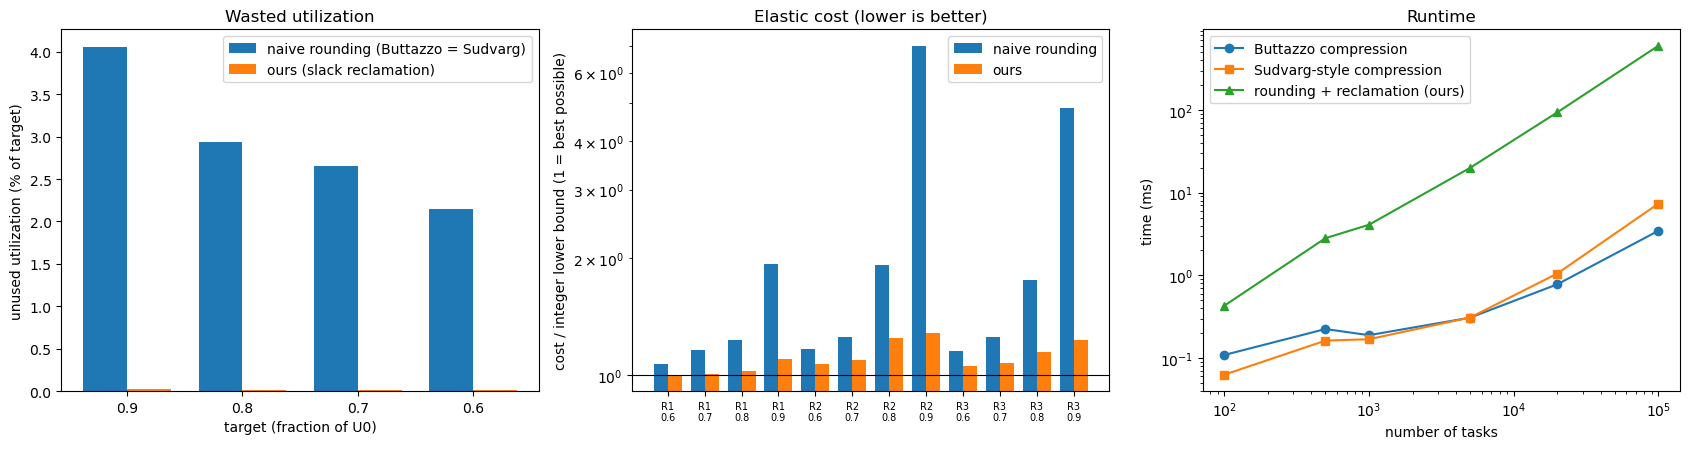

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

g = res.groupby("frac")[["unused_pct_naive", "unused_pct_ours"]].mean().sort_index(ascending=False)
x = np.arange(len(g)); w = 0.38
ax[0].bar(x - w/2, g.unused_pct_naive, w, label="naive rounding (Buttazzo = Sudvarg)")
ax[0].bar(x + w/2, g.unused_pct_ours, w, label="ours (slack reclamation)")
ax[0].set_xticks(x); ax[0].set_xticklabels([f"{f}" for f in g.index])
ax[0].set_xlabel("target (fraction of U0)"); ax[0].set_ylabel("unused utilization (% of target)")
ax[0].set_title("Wasted utilization"); ax[0].legend()

g2 = res.groupby(["rule", "frac"])[["sudvarg_gap", "ours_gap"]].mean().reset_index()
labels = [f"{r}\n{f}" for r, f in zip(g2.rule, g2.frac)]
x = np.arange(len(g2))
ax[1].bar(x - w/2, g2.sudvarg_gap, w, label="naive rounding")
ax[1].bar(x + w/2, g2.ours_gap, w, label="ours")
ax[1].set_yscale("log"); ax[1].axhline(1, color="k", lw=0.8)
ax[1].set_xticks(x); ax[1].set_xticklabels(labels, fontsize=7)
ax[1].set_ylabel("cost / integer lower bound (1 = best possible)"); ax[1].set_title("Elastic cost (lower is better)"); ax[1].legend()

ax[2].loglog(scaling.tasks, scaling.buttazzo_ms, "o-", label="Buttazzo compression")
ax[2].loglog(scaling.tasks, scaling.sudvarg_style_ms, "s-", label="Sudvarg-style compression")
ax[2].loglog(scaling.tasks, scaling.rounding_plus_reclamation_ms, "^-", label="rounding + reclamation (ours)")
ax[2].set_xlabel("number of tasks"); ax[2].set_ylabel("time (ms)"); ax[2].set_title("Runtime"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/comparison_charts.png", dpi=150); plt.show()

## 11. Export: Excel workbook and CSV

In [16]:
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

F = "Arial"; BF = Font(name=F, bold=True, size=10); NF = Font(name=F, size=10); TF = Font(name=F, bold=True, size=14)
HF = PatternFill("solid", fgColor="D9E1F2"); GF = PatternFill("solid", fgColor="E2EFDA")
thin = Side(style="thin", color="999999"); BX = Border(left=thin, right=thin, top=thin, bottom=thin)

def write_table(ws, r0, df, fmts=None, widths=None, hl=()):
    for j, h in enumerate(df.columns, 1):
        c = ws.cell(r0, j, h); c.font = BF; c.fill = HF; c.border = BX
        c.alignment = Alignment(wrap_text=True, horizontal="center", vertical="center")
    ws.row_dimensions[r0].height = 46
    for i, row in enumerate(df.itertuples(index=False), 1):
        for j, v in enumerate(row, 1):
            if isinstance(v, (np.floating, np.integer)): v = v.item()
            c = ws.cell(r0 + i, j, v); c.font = NF; c.border = BX
            if fmts and fmts.get(df.columns[j-1]): c.number_format = fmts[df.columns[j-1]]
            if df.columns[j-1] in hl: c.fill = GF
    for j in range(1, len(df.columns) + 1):
        ws.column_dimensions[get_column_letter(j)].width = (widths or {}).get(df.columns[j-1], 15)
    return r0 + len(df) + 1

wb = Workbook()
ws = wb.active; ws.title = "Overview"
ws["A1"] = "Comparative study: elastic scheduling with integer periods"; ws["A1"].font = TF
info = [
 ("Methods", "Conventional (drops tasks) | Buttazzo + naive rounding | Sudvarg-style + naive rounding | Ours: Slack Reclamation"),
 ("TrustMotion runs", f"{len(res):,} runs on {res.core_set.nunique():,} core task sets"),
 ("Unused utilization, % of target: naive / ours", f"{overall.unused_pct_naive:.3f} / {overall.unused_pct_ours:.3f}"),
 ("Cost / integer lower bound: naive / ours", f"{overall.sudvarg_gap:.3f} / {overall.ours_gap:.3f}   (1.0 = best possible)"),
 ("Average cost reduction of ours vs naive rounding (%)", f"{overall.cost_red:.2f}"),
 ("Runs where ours is strictly better (%) / worse (count)", f"{overall.better:.2f} / {int((res.ours_gap > res.sudvarg_gap + 1e-12).sum())}"),
 ("Conventional: tasks dropped on average (%)", f"{overall.dropped_pct:.1f}"),
 ("Real data", "GAP (17 tasks), Hartstone (5 tasks); TrustMotion instances are generated from real automotive statistics"),
 ("Elastic parameters", "Our own rules from C and T: Tmin=T, Tmax=T(2-U), E: R1=C/T, R2=T/C, R3=T"),
 ("Integer grid", "whole milliseconds, never below Tmin"),
 ("Conventional cost", "not comparable (dropping a task is not a longer period); only unused utilization and tasks dropped are reported"),
]
for i, (a, b) in enumerate(info, 3):
    ws.cell(i, 1, a).font = BF; c = ws.cell(i, 2, b); c.font = NF; c.alignment = Alignment(wrap_text=True)
ws.column_dimensions["A"].width = 52; ws.column_dimensions["B"].width = 100

def sheet(name, title, df, fmts=None, widths=None, hl=()):
    w = wb.create_sheet(name); w["A1"] = title; w["A1"].font = TF
    write_table(w, 3, df, fmts, widths, hl)

sheet("TrustMotion summary", "TrustMotion: by elastic rule and target", summary.round(4), hl=("Unused % Ours", "Cost/bound Ours"))
sheet("TrustMotion by bucket", "TrustMotion: by instance size bucket", by_bucket.round(4))
for name in small:
    sheet(name, f"{name}: all methods", small_res[small_res.dataset == name].drop(columns="dataset").round(6), hl=("unused_ours", "cost_ours"))
sheet("Runtime", "Runtime on tiled real tasks (rule R2, 70% of U0)", scaling.round(4))
wb.save(f"{OUT_DIR}/comparative_study.xlsx")

cols = ["bucket", "core_set", "rule", "frac", "n", "U0", "Ud", "ideal_cost", "grid_bound_cost", "conv_dropped", "conv_unused",
        "buttazzo_unused", "sudvarg_unused", "ours_unused", "buttazzo_cost_ratio", "sudvarg_cost_ratio", "ours_cost_ratio",
        "buttazzo_gap", "sudvarg_gap", "ours_gap", "ours_moves", "t_buttazzo_us", "t_sorted_us", "t_ours_extra_us"]
res[cols].round(8).to_csv(f"{OUT_DIR}/trustmotion_results_all_methods.csv", index=False)
small_res.round(8).to_csv(f"{OUT_DIR}/small_datasets_results.csv", index=False)
print("written to", os.path.abspath(OUT_DIR), ":", sorted(os.listdir(OUT_DIR)))

written to c:\Users\parth\Desktop\RealTimeOs\results : ['comparative_study.xlsx', 'comparison_charts.png', 'small_datasets_results.csv', 'trustmotion_results_all_methods.csv']


## 12. What to say in the report

* **Result.** Slack reclamation removes almost all of the utilization wasted by integer rounding (about 3 % of the target with naive rounding, about 0.015 % with ours) and brings the elastic cost close to the best possible integer-period solution. It is never worse than naive rounding in any run.
* **Not a speed claim.** It is an extra step after compression and costs extra time.
* **Buttazzo and Sudvarg-style give identical results**; they differ only in runtime. The Sudvarg-style code here is my own implementation of the sorted-threshold idea.
* **Data.** Task parameters come from published real task sets (GAP, Hartstone) and a benchmark generated from real automotive statistics (TrustMotion). The elastic parameters are our own documented assumptions, tested under three rules and four overload levels.
* **Cost caveat.** The conventional method's elastic cost is not comparable, so only unused utilization and tasks dropped are reported for it.
* **Related work to cite:** Bhat and Rajkumar (arXiv:2302.03724) assign integer harmonic periods, but only periods no larger than the originals and without elastic compression, so it is a different problem.